In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from PyLTSpice.editor.spice_editor import SpiceEditor

import utils.ltspice_tools as lt
import utils.raw as rw

BASE_DIR = Path("..") / "models" / "operational-amplifier"

## Voltage Follower

In [2]:

asc_file = (BASE_DIR /"voltage_follower.asc").resolve()
raw_path = lt.run_sim(asc_file, analysis_card=".ac dec 100 100000 10000000", wait_seconds=60)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)
lt.clear_sim_outputs(asc_file)

e:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\.venv\Lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
e:\X\Programming_Workspace\Python_Workspace\LTSpice_Python_Automation\.venv\Lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


(100, 10000.0)

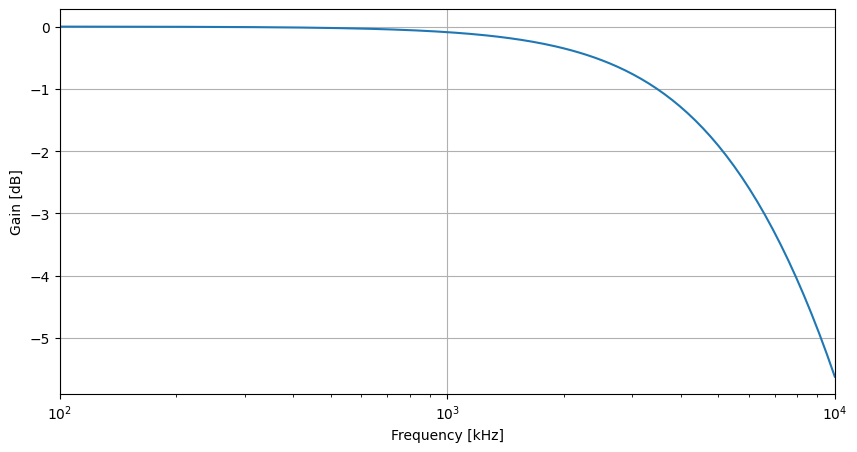

In [3]:
# Plotting
freq = df["frequency"].values / 1000
v_in = df["V(in)"].values
v_out = df["V(out)"].values
G = 20 * np.log10(np.abs(v_out / v_in))



fig,ax = plt.subplots(figsize=(10, 5))
ax.semilogx(freq, G)

ax.set_xlabel("Frequency [kHz]")
ax.set_ylabel("Gain [dB]")
ax.grid(True)
ax.set_xlim(100, 1e4)

# Optionally save the figure
# fig.savefig("voltage_follower.png")


## Non-inverting

In [4]:

asc_file = (BASE_DIR /"non_inverting.asc").resolve()
raw_path = lt.run_sim(asc_file, analysis_card=".ac dec 100 100000 10000000", wait_seconds=150)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)
lt.clear_sim_outputs(asc_file)

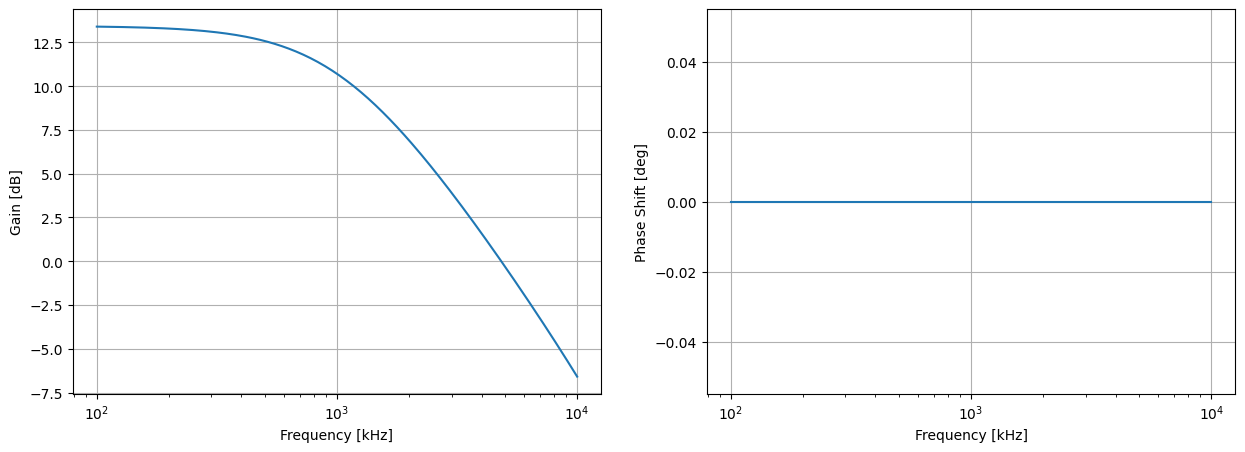

In [5]:
freq = df["frequency"].values / 1000
v_in = df["V(in)"].values
v_out = df["V(out)"].values
G = 20 * np.log10(np.abs(v_out / v_in))
phase = np.angle(v_out / v_in, deg=True)



fig,ax = plt.subplots(nrows=1, ncols = 2, figsize=(15, 5))
ax[0].semilogx(freq, G)
ax[0].set_xlabel("Frequency [kHz]")
ax[0].set_ylabel("Gain [dB]")
ax[0].grid(True)

ax[1].semilogx(freq, phase)
ax[1].set_xlabel("Frequency [kHz]")
ax[1].set_ylabel("Phase Shift [deg]")
ax[1].grid(True)

# Optionally save the figure
# fig.savefig("non_inverting.png")

## Inverting

In [6]:

asc_file = (BASE_DIR /"inverting.asc").resolve()
raw_path = lt.run_sim(asc_file, analysis_card=".ac dec 100 100000 10000000", wait_seconds=150)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)
lt.clear_sim_outputs(asc_file)

(100, 10000.0)

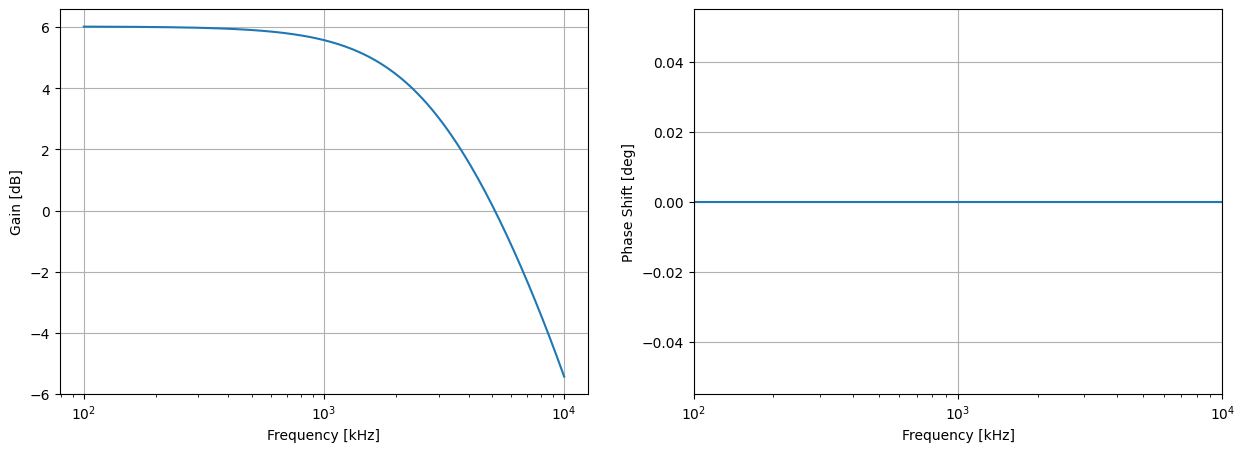

In [7]:
freq = df["frequency"] / 1000
v_in = df["V(in)"]
v_out = df["V(out)"]
G = 20 *np.log10(np.abs(v_out/ v_in))
phase = np.angle(v_out/v_in, deg=True)



fig,ax = plt.subplots(nrows=1, ncols = 2, figsize=(15, 5))
ax[0].semilogx(freq, G)
ax[0].set_xlabel("Frequency [kHz]")
ax[0].set_ylabel("Gain [dB]")
ax[0].grid(True)

ax[1].semilogx(freq, phase)
ax[1].set_xlabel("Frequency [kHz]")
ax[1].set_ylabel("Phase Shift [deg]")
ax[1].grid(True)
ax[1].set_xlim(100, 1e4)

# Optionally save the figure
#fig.savefig("inverting.png")

## Inverting amplifier dynamic behaviour

In [8]:

asc_file = (BASE_DIR /"inverting.asc").resolve()
raw_path = lt.run_sim(asc_file, analysis_card=".dc V3 -6 6 0.1", wait_seconds=60)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)
lt.clear_sim_outputs(asc_file)

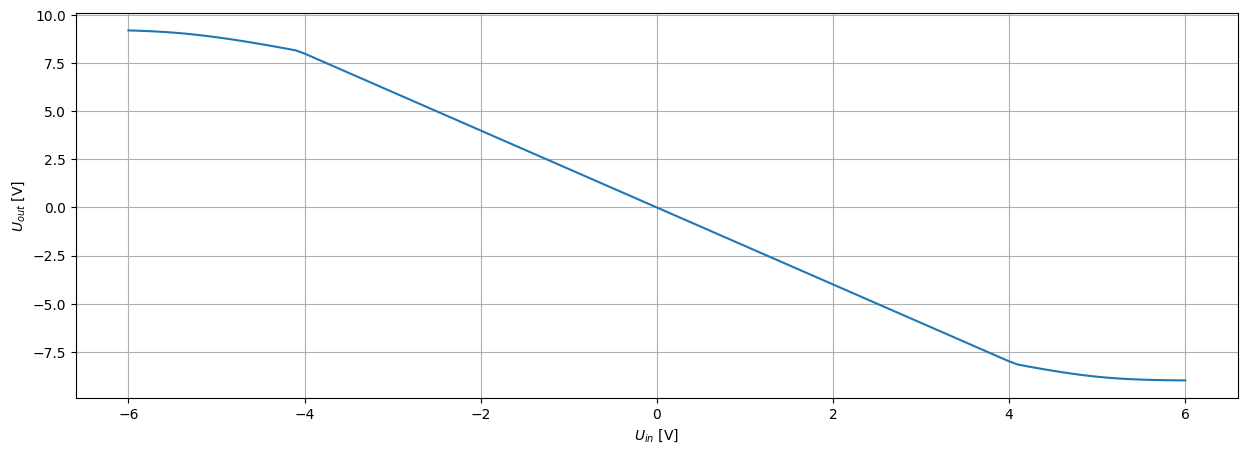

In [9]:
v_in = df["V(in)"]
v_out = -df["V(out)"]

fig,ax = plt.subplots(figsize=(15, 5))
ax.plot(v_in, v_out)

ax.set_xlabel("$U_{in}$ [V]")
ax.set_ylabel("$U_{out}$ [V]")
ax.grid(True)

## Ideal diode circuit

In [10]:

asc_file = (BASE_DIR /"ideal_diode.asc").resolve()
raw_path = lt.run_sim(asc_file, analysis_card=".dc V3 -6 6 0.1", wait_seconds=60)
rr = rw.read_raw(raw_path)
df = rw.raw_to_dataframe(rr)
lt.clear_sim_outputs(asc_file)

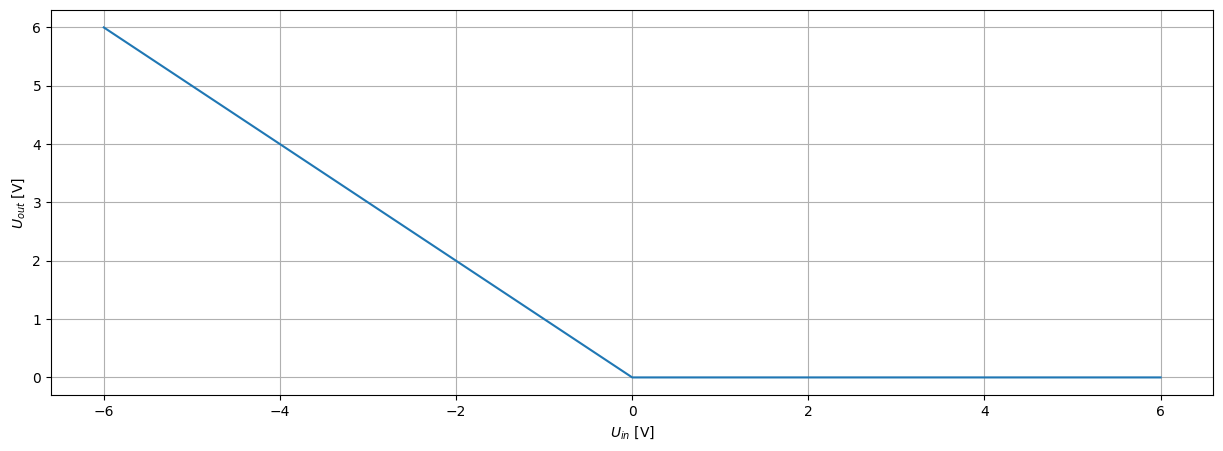

In [11]:
v_in = df["V(in)"].values
v_out = df["V(out)"].values

fig,ax = plt.subplots(figsize=(15, 5))

ax.plot(v_in, v_out)


ax.set_xlabel("$U_{in}$ [V]")
ax.set_ylabel("$U_{out}$ [V]")
ax.grid(True)